This code is tailored to what I want to achieve. Some hyperparameters are selective and conditional...

overview

1. create 10000 topology dataset: get sample_a: (l(oadpoint), t(heta), v(olfrac)) -> topology dictionary

2. Train (beta) VAE model with sample_a: get sample_a: (l, t, v) -> latent vector dictionary

3. create 2500 topology dataset: get sample_b: (l, t, v) -> topology dictionary

4. query latent vector of sample_b's (l, t, v) from sample_a dictionary; restore, and compare compliance with the original topology. (neighbors weighted from k-NN, )

Dependency: the right-hand process must be done after altering the left-hand: 1->2, 3->4

otherwise independent.

바꿔볼 것: 
k (Nearest Neighbors): 바꾸기 쉬움. 5, 


k-nearest neighbor을 사용한 interpolation의 원리:
1. k 개의 가장 가까운 이웃을 찾는다.
2. 이 5개의 이웃에 대해 가장 가까운 사람들을 찾는다.


beta (regularization for ...): 바꾸기 어려움 (다시 학습시켜야 함.) 일단 두 가지 1과 0.5 옵션만 가지고 있음.

SIMP sampler 정의: 초기조건을 무작위로 정해 topology를 원하는 개수만큼 만들고 sample dictionary 를 리턴한다.

(l, t, v) -> [topology directory, latent mapping (초기: None)]

topology directory 및 파일의 이름에 (l, t, v) 튜플에 대한 hash 값을 사용했다.

In [2]:
import numpy as np
import pickle

import os

def createFolder(directory): # unused in this scope
    try:
        if not os.path.exists(directory):
            os.makedirs(directory)
    except OSError:
        print ('Error: Creating directory. ' +  directory)

In [3]:
from topopt_cholmod import main
from bc_options import Simple

class SIMP_sampler():
    def __init__(self, base): # default setting with base directory as argument
        self.base = base
        createFolder(base)

        self.nelx, self.nely = 64, 32
        self.rmin = 2.0
        self.penal, self.ft = 3.0, 1
        
        self.bc, self.side = Simple, 3
        self.test = self.bc(self.nelx, self.nely, self.side)

    def sample(self, amount=None, l=None, t=None, v=None):
        if isinstance(amount, int) and amount>0:
            results = {}
            i = 0
            while(i<amount):
                l=np.random.randint(0, 64)
                t=np.random.uniform(0, 2*np.pi)
                v=np.random.uniform(0.2, 0.8)
                dirname = self.base + "/" + str(hash((l, t, v)))
                try:
                    main(self.nelx, self.nely, v, self.penal, self.rmin, self.ft,
                         self.test.fixed, self.test.lp2f(65+l*33, t), dirname)
                    results.update({(l, t, v): [dirname, None]})
                    i += 1
                except:
                    pass # sometimes the SIMP does not converge with various reasons.
            return results
        else: # l, t, v is given as parameters
            dirname = self.base + "/" + str(hash((l, t, v)))
            try:
                main(self.nelx, self.nely, v, self.penal, self.rmin, self.ft,
                     self.test.fixed, self.test.lp2f(65+l*33, t), dirname)
            except:
                return {(l, t, v): [dirname, None]} # sometimes the SIMP does not converge with various reasons.

sampler_a 는 학습용 토폴로지를 담는다. 10000개를 생성했다.

In [ ]:
# XXX 10000 sample generator!!! don't touch this!!!
base = "sample_a"
sampler_a = SIMP_sampler(base)
sample_a = sampler_a.sample(10000) # creates samples this much

VAE part

In [4]:
# prerequisites
import torch
import torch.nn.functional as F
import torch.optim as optim

from VAE import VAE

from matplotlib import colors
import matplotlib.pyplot as plt

import os
import pandas as pd
from torch.utils.data import Dataset, DataLoader

torch.backends.cudnn.benchmark = True

데이터 셋 정의: sample dictionary 로 초기화한다. 인덱스에 따라 CSV 파일을 데이터프레임으로 불러오고 초기조건 튜플 (l, t, v)을 가져온다.

In [5]:
class CSVDataset(Dataset):
    def __init__(self, sample):
        self.sample = sample

    def __len__(self):
        return len(self.sample)

    def __getitem__(self, idx):
        key = list(self.sample.keys())[idx]
        file_path = self.sample[key][0]+".csv"
        data = pd.read_csv(file_path, header=None, index_col=False).values
        data = data.astype('float32')

        assert data.shape == (64, 32), f"Data shape mismatch: got {data.shape}, expected (64, 32)"

        return torch.tensor(data), key

학습, 테스트용 데이터 셋 로더 인스턴스 만들기

데이터 로더는 데이터셋과 배치 사이즈를 지정해서 넘긴다.

In [8]:
bs = 32

# Create datasets
train_dataset = CSVDataset(sample_a)
test_dataset = CSVDataset(sample_a)

# Data Loader (Input Pipeline)
train_loader = DataLoader(dataset=train_dataset, batch_size=bs, shuffle=True, num_workers=0)
test_loader = DataLoader(dataset=test_dataset, batch_size=bs, shuffle=False, num_workers=0)

모델 인스턴스

z_dim = 16

모델은 MLP로 2048 (=64* 32) -> 512 -> 256 -> 16 -> 256 -> 512 -> 2048 (=64* 32) 의 FCN 레이어를 사용함.

Activation 함수는 ReLU를 사용함. (더 자세한 설명은 VAE.py를 보면서 해야 할 것 같다.)

In [6]:
# build model
z_dim = 16
vae = VAE(x_dim=64*32, h_dim1= 512, h_dim2=256, z_dim=z_dim)
if torch.cuda.is_available():
    vae.cuda()

vae

VAE(
  (fc1): Linear(in_features=2048, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc31): Linear(in_features=256, out_features=16, bias=True)
  (fc32): Linear(in_features=256, out_features=16, bias=True)
  (fc4): Linear(in_features=16, out_features=256, bias=True)
  (fc5): Linear(in_features=256, out_features=512, bias=True)
  (fc6): Linear(in_features=512, out_features=2048, bias=True)
)

VAE를 위한 Loss 함수 지정 (beta VAE; beta=1 then normal VAE, if 0~1 then KL divergence regularized beta VAE)

+ 최적화 알고리즘 (Adam optimizer)

In [5]:
beta = 0.5
# return reconstruction error + KL divergence losses
def loss_function(recon_x, x, mu, log_var, beta=1.0):
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 64*32), reduction='sum')
    KLD = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return BCE + beta * KLD

optimizer = optim.Adam(vae.parameters())

NameError: name 'vae' is not defined

VAE train, test 함수 정의; train loop (1000 epoch)

In [6]:
def train(epoch):
    vae.train()
    train_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.cuda()
        optimizer.zero_grad()
        
        recon_batch, mu, log_var = vae(data)
        loss = loss_function(recon_batch, data, mu, log_var)
        
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
        
        # if batch_idx % 100 == 0:
        #     print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
        #         epoch, batch_idx * len(data), len(train_loader.dataset),
        #         100. * batch_idx / len(train_loader), loss.item() / len(data)))
    print('====> Epoch: {} Average loss: {:.4f}'.format(epoch, train_loss / len(train_loader.dataset)))

In [7]:
def test():
    vae.eval()
    test_loss= 0
    with torch.no_grad():
        for data, _ in test_loader:
            data = data.cuda()
            recon, mu, log_var = vae(data)
            
            # sum up batch loss
            test_loss += loss_function(recon, data, mu, log_var).item()
        
    test_loss /= len(test_loader.dataset)
    print('====> Test set loss: {:.4f}'.format(test_loss))

In [ ]:
# XXX train loop
for epoch in range(1, 1000):
    train(epoch)
    if (epoch%100 == 0):
        test()

모델 저장 및 불러오기

In [27]:
# XXX Save the entire model
torch.save(vae, "vae_16_beta_0_5.pth")

In [25]:
# Load the entire model
vae = torch.load("vae_16_beta_0_5.pth")

# Set to evaluation mode (if needed)
vae.eval()

 C:\Users\User\AppData\Local\Temp\ipykernel_13268\88894459.py:2: FutureWarning:You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


VAE(
  (fc1): Linear(in_features=2048, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc31): Linear(in_features=256, out_features=16, bias=True)
  (fc32): Linear(in_features=256, out_features=16, bias=True)
  (fc4): Linear(in_features=16, out_features=256, bias=True)
  (fc5): Linear(in_features=256, out_features=512, bias=True)
  (fc6): Linear(in_features=512, out_features=2048, bias=True)
)

복원용 로더, 복원 디렉터리 지정 (일부 (15개) 복원: 단순히 시각적 확인용.)

In [10]:
input_loader = DataLoader(dataset=train_dataset, batch_size=1, shuffle=False)

In [28]:
base = "sample_a"
reconstructed_dir = base+"/reconstructed_beta_0_5"
os.makedirs(reconstructed_dir, exist_ok=True)

latent 맵핑 -> sample_a dictionary에 저장 (+ 15개 복원된 결과 확인.)

In [ ]:
with torch.no_grad():
    for batch_idx, (data, key) in enumerate(input_loader):
        # Move data to GPU if available
        data = data.cuda()
        key = tuple(_.tolist()[0] for _ in key) # Better implementation...?
        restored, latent, _ = vae.forward(data)
        sample_a[key][1] = latent

        if (batch_idx < 15): # 일부는 시각적 확인을 위해 복원.
            pd.DataFrame(data.cpu().view(64, 32)).to_csv(f'{reconstructed_dir}/{batch_idx}_data.csv', index=False, header=False)
            pd.DataFrame(restored.cpu().view(64, 32)).to_csv(f'{reconstructed_dir}/{batch_idx}_rest.csv', index=False, header=False)

        # save_image(data.view(1, 1, 64, 32), f'./vae_output/{batch_idx}_data' + '.png')
        # save_image(restored.view(1, 1, 64, 32), f'./vae_output/{batch_idx}_restored' + '.png')

from csv2fig import csv2fig
csv2fig(reconstructed_dir, reconstructed_dir, False)

In [30]:
# XXX Saving the object:
with open('sample_a_10000_beta_0_5.pkl', 'wb') as f:
    pickle.dump(sample_a, f)

In [7]:
# Getting back the objects:
with open('sample_a_10000_beta_0_5.pkl', 'rb') as f:
    sample_a = pickle.load(f)

len(sample_a)
item0 = list(sample_a.items())[0]
hash(item0[0]), item0

c:\Users\User\anaconda3\Lib\site-packages\torch\storage.py:414: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(io.BytesIO(b))


(2805767781618130613,
 ((13, 1.596857200729862, 0.3364091936975495),
  ['sample_a/2805767781618130613',
   tensor([[ 1.6791, -0.3036, -0.0710, -0.5935,  0.0183,  1.3174,  0.3435,  1.4590,
             0.0399,  1.1763, -0.0976, -1.5482,  0.0321,  0.0764, -0.0928,  0.0741]],
          device='cuda:0')]))

# 여기서부터...

standardization (표준 분포) vs normalization (0~1, based on parameter range)

Normalization으로 선택함.

In [9]:
import numpy as np
from sklearn.preprocessing import StandardScaler

"""Given sample pair data, create interpolation for new data.

The pair: input - output

- input: 3 dimensional (loadpoint, theta, volfrac)
  - loadpoint: "discrete", 65, 98, ..., 2144 (65+33k, k=0~63) -> use k instead
  - theta: continuous, 0~2*pi
  - volfrac: continuous, 0.2 ~ 0.8
- output: n dimensional
  - n depends on latent space dimension....
"""

def normalize_X(X_train):
    normalized = []
    for l, t, v in tuple(X_train):
        l_norm = l / 63  # Normalize l
        t_norm = t / (2 * np.pi)  # Normalize t
        v_norm = (v - 0.2) / (0.8 - 0.2)  # Normalize v
        normalized.append((l_norm, t_norm, v_norm))
    return np.array(normalized)

효과적인 interpolation을 위한 sample_a 전처리 (Normalization)

In [10]:
# Sample input-output data
X_train = np.array(list(sample_a.keys()))  # 3D inputs with different ranges
Y_train = np.array([_[1].cpu().numpy().squeeze() for _ in sample_a.values()])  # Shape: (N, 10)

# Step 1: Normalize inputs
scaler = StandardScaler() # will not use if normalization instead of standardization
# X_train_normalized = scaler.fit_transform(X_train)
X_train_normalized = normalize_X(X_train)

Interpolation method: K-NN weighted sum

Some considerations: k 값 설정 (근데 5 정도도 괜찮은 것 같아 보인다.) -> 실험 필요.

Interpolation 방법:

1. (l, t, v) query에 대해, 가장 가까운 k(=5)개의 점 및 거리를 찾는다. (거리 = 0인 경우 방지를 위해 기본적으로 1e-8만큼 더한다.)

2. 각 점의 latent mapping의 값을 가져온다.

3. 거리의 역수를 무게로 해서 weighted average를 interpolation 값으로 삼는다.


왜 k-NN이 짱이고 이것을 선택했는지에 대한 이론이 필요함.

In [22]:
from sklearn.neighbors import NearestNeighbors

def knn_nbrs(X_train, k=5):
    nbrs = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(X_train)
    return nbrs


def knn_interpolation(nbrs, Y_train, X_query): # Hyperparameter: 5 is okay I guess
    distances, indices = nbrs.kneighbors(X_query)
    
    # Compute weights (inverse distance)
    weights = 1 / (distances + 1e-8)  # Avoid division by zero
    weights /= np.sum(weights, axis=1, keepdims=True)  # Normalize weights
    
    # Compute weighted average of neighbors' outputs
    Y_query = np.einsum('ij,ijk->ik', weights, Y_train[indices])
    return Y_query

Interpolation: Gaussian Process, GP (with Radial basis function, RBF)

In [12]:
# 필요한 라이브러리 설치 및 임포트
import numpy as np
import GPy

def gp_model(X_train, Y_train):    # 입력 데이터 X와 출력 데이터 Y 준비
    # 2. GPR 모델 정의
    # RBF 커널 정의 (input_dim=3: 입력 차원, 초기 variance와 lengthscale (커널 스무딩) 설정)
    kernel = GPy.kern.RBF(input_dim=3, variance=1.0, lengthscale=1.0)

    # Gaussian Process Regression 모델 생성
    m = GPy.models.GPRegression(X_train, Y_train, kernel)
    # m = GPy.models.SparseGPRegression(X_train, Y_train, kernel, num_inducing=500)

    # 3. 모델 최적화
    # 최적화 실행 (파라미터를 조정하여 모델 성능 향상)
    m.optimize_restarts(num_restarts=5)
    return m


def gp_predict(m, X_query):
    # 4. 새로운 데이터에 대한 예측
    # GPR 모델을 사용해 예측값 및 예측 불확실성 계산
    predictions, uncertainties = m.predict(X_query)
    return predictions  # 6. 결과 출력

sample_b: 검증용 데이터셋 만들기. 2500개를 새로 만든다.

In [17]:
target = "sample_b_beta_0.5"

In [ ]:
# XXX 2500 sample generator! don't touch this!!!
# please flush sample_b folder before desired sample generation, if necessary.

target = "sample_b_beta_0.5"

sampler_b = SIMP_sampler(target)
sample_b = sampler_b.sample(2500) # creates sample; 116m  20.4s
ltv_list = [list(_) for _ in sample_b.keys()]
print(ltv_list)

from csv2fig import csv2fig
csv2fig(target, f"{target}/sample_b", False)

In [ ]:
# HACK Query point (normalize it using the same scaler)
X_query = np.array(ltv_list)  # Example query point in 3D
print(X_query.shape)
# X_query_normalized = scaler.transform(X_query)
X_query_normalized = normalize_X(X_query)

# Step 2: Perform k-NN interpolation
# Get interpolated output
Y_query = [knn_interpolation(X_train_normalized, Y_train, X_query_normalized, k=5) for _ in X_query_normalized]

print("Interpolated Output:", Y_query)
len(Y_query)

sample_b 에서 데이터셋 만들기

In [15]:
# Create datasets
compare_dataset = CSVDataset(sample_b)

# Data Loader (Input Pipeline)
bs = 1
compare_loader = DataLoader(dataset=compare_dataset, batch_size=bs, shuffle=True)

이제 컴플라이언스 비교를 해보자.

Method: from sample_b (= testing), you can get a 3, 16_real pair.

    You do this by simply sampling a bunch of samples.

from 3, you can get 16_interpolated.

    You do this by simply 

from 3, you can get the correct condition.

    You do this by simple conversion done from for sample_a.

With the correct condition, you can use FEA_Comp's fea_c to calculate the compliance.

    Done!

k-nn interpolation result (2500개, 6m 55.9s)

왜 이렇게 오래 걸리는가를 생각해보면... 글쎄 진짜 모르겠다.

일부분만 시각적 확인은 해 보도록 한다.

30/30
30/30


4.218463769717006

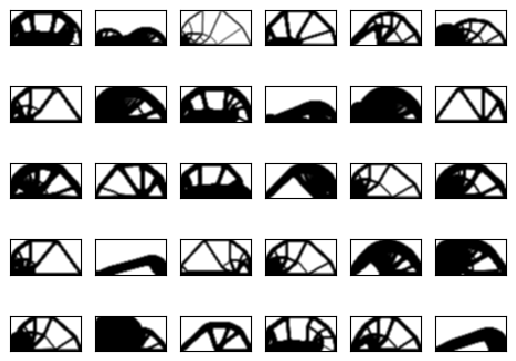

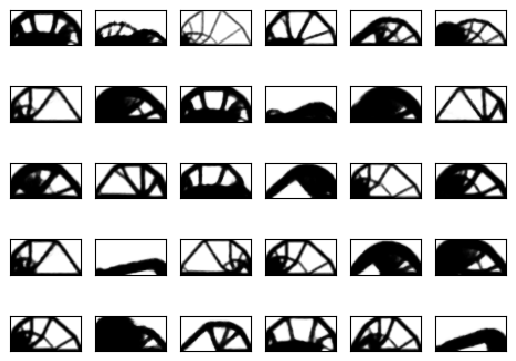

In [40]:
k=1
nbrs = knn_nbrs(X_train_normalized, k=k)

from FEA_Comp import fea_c
from bc_options import Simple

nelx, nely = 64, 32
rmin = 2.0
penal, ft = 3.0, 1

bc, side = Simple, 3
test = bc(nelx, nely, side)

createFolder(f"{target}/knn_{k}/sample_b_order")
createFolder(f"{target}/knn_{k}/sample_b_rest")

c0_list = []
c1_list = []
c_erosion = []

with torch.no_grad():
    for batch_idx, (data, key) in enumerate(compare_loader):
        # Move data to GPU if available
        data = data.cuda()
        key = tuple(_.tolist()[0] for _ in key) # Better implementation...?
        # print(key)
        interpolated = knn_interpolation(nbrs, Y_train, normalize_X([key]))
        sample_b[key][1] = interpolated
        restored = vae.decoder(torch.tensor(interpolated, dtype=torch.float).cuda())

        # from key, we can construct correct condition for fea_c.
        l, t, v = key

        # the original
        p0 = pd.DataFrame(data.cpu().view(64, 32))
        c0 = fea_c(nelx, nely, v, penal, rmin, ft, test.fixed, test.lp2f(65+l*33, t), p0.to_numpy())

        # the reconstructed
        p1 = pd.DataFrame(restored.cpu().view(64, 32))
        c1 = fea_c(nelx, nely, v, penal, rmin, ft, test.fixed, test.lp2f(65+l*33, t), p1.to_numpy())

        c0_list.append(c0)
        c1_list.append(c1)
        c_erosion.append(c1 - c0)

        if (batch_idx < 30): # 일부는 시각적 확인을 위해 복원.
            p0.to_csv(f'{target}/knn_{k}/sample_b_order/{batch_idx}.csv', index=False, header=False)
            p1.to_csv(f'{target}/knn_{k}/sample_b_rest/{batch_idx}.csv', index=False, header=False)

from csv2fig import csv2fig
csv2fig(f"{target}/knn_{k}/sample_b_order", f"{target}/knn_{k}/sample_b_order", False)
csv2fig(f"{target}/knn_{k}/sample_b_rest", f"{target}/knn_{k}/sample_b_rest", False)

sum(c_erosion)/len(c_erosion)

In [22]:
# XXX Saving the object:
with open('sample_b_2500_beta_0_5_knn_5.pkl', 'wb') as f:
    pickle.dump(sample_b, f)

In [14]:
# Getting back the objects:
with open('sample_b_2500_beta_0_5_knn_5.pkl', 'rb') as f:
    sample_b = pickle.load(f)

len(sample_b)
item0 = list(sample_b.items())[0]
hash(item0[0]), item0

(8224126981155559108,
 ((21, 3.7318255789955432, 0.33488123317040436),
  ['sample_b_beta_0.5/8224126981155559108',
   array([[-0.55248962, -0.12118578, -0.05934989, -0.65405314, -0.02209763,
            0.96815565, -1.44592911,  1.57448423,  0.05451078, -0.47764716,
           -0.06196238,  1.202879  ,  0.01675888,  0.02276593, -0.01034118,
           -0.00681212]])]))

In [41]:
print(len(c_erosion))
c_sorted = sorted(c_erosion, reverse=False)
c_sorted[0], c_sorted[-1]

2500


(-7.173335006050074, 2472.217171925336)

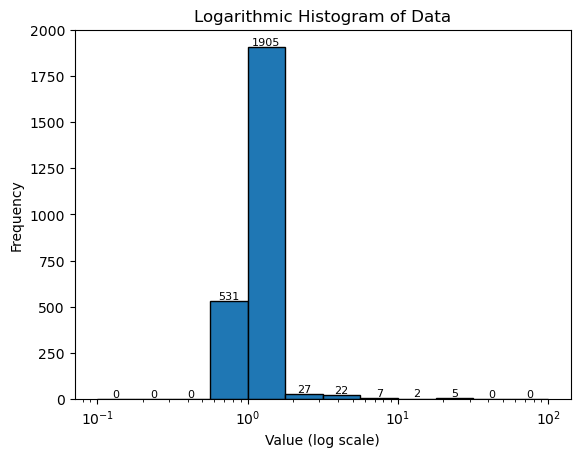

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# Create a histogram with logarithmic bins
bins = np.logspace(-1, 2, 13)  # Create bins spaced logarithmically

counts, bin_edges, _ = plt.hist([(b / a) for a, b in zip(c0_list, c1_list)], bins=bins, edgecolor='black')

# Set the x-axis to a logarithmic scale
plt.xscale('log')

# Add titles and labels
plt.title('Logarithmic Histogram of Data')
plt.xlabel('Value (log scale)')
plt.ylabel('Frequency')

for count, x in zip(counts, bin_edges):
    plt.text(x*10**(0.125), count + 0.5, str(int(count)), ha='center', va='bottom', fontsize=8)

# Show the plot
plt.show()

(deprecated?) For Gaussian Process interpolation (very bad result compared)

In [ ]:
import numpy as np

# Randomly select ### indices from the dataset
indices = np.random.choice(X_train_normalized.shape[0], size=10000, replace=False) # 74m 51.3s

# Subset both X_train_normalized and Y_train
X_subset = X_train_normalized[indices]
Y_subset = Y_train[indices]

# Train the model on the subset
m = gp_model(X_subset, Y_subset)

In [ ]:
createFolder(f"{target}/gp/sample_b_order")
createFolder(f"{target}/gp/sample_b_rest")

with torch.no_grad():
    for batch_idx, (data, key) in enumerate(compare_loader):
        # Move data to GPU if available
        data = data.cuda()
        key = tuple(_.tolist()[0] for _ in key) # Better implementation...?
        print(key)
        interpolated = gp_predict(m, normalize_X([key]))
        sample_b[key][1] = interpolated
        restored = vae.decoder(torch.tensor(interpolated, dtype=torch.float).cuda())

        pd.DataFrame(data.cpu().view(64, 32)).to_csv(f'{target}/{"gp/sample_b_order"}/{batch_idx}.csv', index=False, header=False)

        p1 = pd.DataFrame(restored.cpu().view(64, 32))
        p1.to_csv(f'{target}/{"gp/sample_b_rest"}/{batch_idx}.csv', index=False, header=False)

        # see glorious(?) reconstructed image one by one:
        # n1 = p1.to_numpy()
        # _,ax = plt.subplots()
        # ax.imshow(-n1.reshape((64,32)).T, cmap='gray', interpolation='none', norm=colors.Normalize(vmin=-1,vmax=0))
        # plt.show()

from csv2fig import csv2fig
csv2fig(f"{target}/gp/sample_b_order", f"{target}/gp/sample_b_order", False)
csv2fig(f"{target}/gp/sample_b_rest", f"{target}/gp/sample_b_rest", False)

In [48]:
sum(c1_list)/len(c1_list)

18.765326663798028